# NIH ChestX-ray14 데이터 특성 및 분할 무결성 분석

## 분석 목적
폐렴 소견 라벨 분류 실험에 앞서 데이터의 클래스 불균형, 반복 촬영 구조, 촬영 자세별 분포를 파악하고, 현재 실험 목록의 분할 무결성을 확인한다.

본 분석은 원본 메타데이터 전체를 대상으로 한 기술적 탐색과 기존 실험 목록의 구조 검증으로 구성된다. 모델 예측이나 성능 평가를 수행하지 않는다. 분석 코드와 결과는 이 프로젝트에서 실제 CSV 및 검수 기록을 사용해 실행하였다. 분석 방법의 신규성이나 라벨의 임상적 정확성을 주장하지 않는다.

### 주요 결과
- 원본 메타데이터: 영상 112,120장, 환자 30,805명.
- Pneumonia 라벨 포함 영상: 1,431장(1.276%).
- 영상 단위 80/20 무작위 분할 시 양쪽에 등장하는 환자: 8,028명.
- 현재 QC 후 실험 목록: 37,673장. 목록 간 환자 중복과 확인된 정확한 픽셀 중복은 0건.

### 데이터 출처 및 재현 정보
- 데이터 제공: NIH Clinical Center.
- [원본 배포처](https://nihcc.app.box.com/v/ChestXray-NIHCC), [사용한 Kaggle 배포본](https://www.kaggle.com/datasets/nih-chest-xrays/data).
- 원본 연구: Wang et al. (2017), *ChestX-ray8: Hospital-scale Chest X-ray Database and Benchmarks on Weakly-Supervised Classification and Localization of Common Thorax Diseases*, CVPR. [논문](https://arxiv.org/abs/1705.02315).
- 입력 CSV: `Data_Entry_2017.csv`. 파일 SHA-256은 아래 실행 결과에서 확인한다. 검수된 이미지 및 분할 목록은 별도 파이프라인에서 준비한 기록을 사용한다.

## 분석 범위
1. 메타데이터 구조 및 결측·파일명 중복
2. 폐렴 라벨 정의와 클래스 분포
3. 환자별 반복 촬영 분포
4. PA/AP별 영상 수와 라벨 비율
5. 영상 단위 분할의 환자 중복 확인
6. 최초 환자 분할과 현재 실험 목록의 무결성 검증

원본 CSV와 기존 분할 목록은 변경하지 않는다. 결과 표와 그래프만 `outputs/metrics/eda/`, `outputs/figures/eda/`에 기록한다.

## 1. 실행 환경 및 경로

프로젝트의 Python 가상환경을 사용한다. 프로젝트 루트 또는 `notebooks/`에서 실행하면 상위 경로에서 데이터 위치를 탐색한다. 다른 위치에서 실행하는 경우 `PROJECT_ROOT`에 프로젝트 경로를 지정한다.

In [1]:
from pathlib import Path
import hashlib
import itertools
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split

PROJECT_ROOT = None  # 자동 탐색 실패 시 프로젝트 경로 지정
if PROJECT_ROOT is None:
    candidates = [Path.cwd(), *Path.cwd().parents]
    PROJECT_ROOT = next((p for p in candidates if (p / "data/raw/Data_Entry_2017.csv").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("기존 프로젝트 폴더에서 실행하거나 PROJECT_ROOT를 지정하세요.")
ROOT = Path(PROJECT_ROOT).resolve()
METRICS = ROOT / "outputs/metrics/eda"
FIGURES = ROOT / "outputs/figures/eda"
METRICS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 12)
print("프로젝트:", ROOT)
print("원본 및 기존 분할: 읽기 전용 분석")

프로젝트: C:\Projects\chest-xray-classification
원본 및 기존 분할: 읽기 전용 분석


## 2. 메타데이터 구조 및 기본 무결성

**분석 단위:** 메타데이터 한 행을 영상 한 장으로 취급한다. `Patient ID`는 환자별 그룹을 정의하는 식별자이며 문자열로 보존한다.

**검사 항목:** 필수 열 존재 여부, 빈 값, 이미지 파일명 중복 여부를 확인한다. 이 검사는 영상 내용이나 라벨 정확성에 대한 검증과 구분한다.

**결과:** 원본 목록은 112,120행과 고유 환자 30,805명으로 구성된다. 검사한 필수 항목의 빈 값과 이미지 파일명 중복은 없다.

In [2]:
csv_path = ROOT / "data/raw/Data_Entry_2017.csv"
source_hash = hashlib.sha256(csv_path.read_bytes()).hexdigest()
df = pd.read_csv(csv_path, dtype=str, keep_default_na=False)
required = ["Image Index", "Patient ID", "Finding Labels", "View Position"]
assert set(required).issubset(df.columns)
print(f"영상 목록 {len(df):,}개 / 환자 {df['Patient ID'].nunique():,}명")
print("입력 CSV SHA-256:", source_hash)
display(df[required].head())
missing = df[required].apply(lambda col: col.str.strip().eq("")).sum().rename("missing_count")
display(missing.to_frame())
assert missing.sum() == 0, "필수 항목 누락 발견"
assert not df["Image Index"].duplicated().any()
print("이미지 파일명 중복: 0개 (영상 내용의 중복 여부는 별도 검사 필요)")

영상 목록 112,120개 / 환자 30,805명
입력 CSV SHA-256: 88f75094e25ccc0c6f1f9cdfd4b2f94f9379a0ae07d5ff4dcf94242707b07462


,Image Index,Patient ID,Finding Labels,View Position
0,00000001_000.png,1,Cardiomegaly,PA
1,00000001_001.png,1,Cardiomegaly|Emphysema,PA
2,00000001_002.png,1,Cardiomegaly|Effusion,PA
3,00000002_000.png,2,No Finding,PA
4,00000003_000.png,3,Hernia,PA


,missing_count
Image Index,0
Patient ID,0
Finding Labels,0
View Position,0


이미지 파일명 중복: 0개 (영상 내용의 중복 여부는 별도 검사 필요)


## 3. 분류 타깃 정의 및 클래스 분포

`Finding Labels`를 `|` 구분자로 분리하고, 정확한 라벨 토큰 `Pneumonia`가 포함된 경우 1, 포함되지 않은 경우 0으로 정의한다. 다른 소견과 Pneumonia가 동시에 기록된 영상도 양성에 포함한다.

**해석 범위:** 음성은 Pneumonia 라벨 부재를 의미한다. 정상 확진이나 모든 질환의 부재를 의미하지 않는다. 보고서에서 자동 추출된 소견 라벨의 한계가 있으므로 이 타깃을 임상 확정 진단과 동일시하지 않는다.

**결과:** 양성 1,431장, 음성 110,689장으로 양성 비율은 1.276%이다. 아래 예시는 타깃 생성 로직과 원본 라벨의 대응을 확인하기 위한 것이다.

In [3]:
label_tokens = df["Finding Labels"].str.split("|", regex=False)
df["pneumonia"] = label_tokens.map(lambda values: int("Pneumonia" in values))
examples = pd.concat([
    df.loc[df.pneumonia.eq(1), ["Image Index", "Finding Labels", "pneumonia"]].head(3),
    df.loc[df.pneumonia.eq(0), ["Image Index", "Finding Labels", "pneumonia"]].head(3),
])
display(examples.reset_index(drop=True))
class_table = df.groupby("pneumonia").size().reindex([0, 1], fill_value=0).rename("images").to_frame()
class_table["percent"] = class_table.images / len(df) * 100
class_table["meaning"] = ["Pneumonia label absent", "Pneumonia label present"]
display(class_table)
class_table.to_csv(METRICS / "class_distribution.csv")

,Image Index,Finding Labels,pneumonia
0,00000013_010.png,Effusion|Pneumonia|Pneumothorax,1
1,00000032_012.png,Atelectasis|Consolidation|Edema|Pneumonia,1
2,00000056_000.png,Nodule|Pneumonia,1
3,00000001_000.png,Cardiomegaly,0
4,00000001_001.png,Cardiomegaly|Emphysema,0
5,00000001_002.png,Cardiomegaly|Effusion,0


,images,percent,meaning
pneumonia,,,
0,110689,98.723689,Pneumonia label absent
1,1431,1.276311,Pneumonia label present


## 4. 불균형의 평가상 의미 및 소견 분포

항상 음성을 예측하는 상수 규칙의 정확도를 계산하여 정확도 단독 보고의 한계를 확인한다. 이 값은 학습 모델의 성능이 아니라 클래스 분포로 결정되는 비교 기준이다.

**결과:** 상수 음성 규칙의 정확도는 98.72%이지만 양성 민감도는 0%이다. 이후 성능 평가는 AUROC뿐 아니라 AUPRC 및 검증 데이터에서 정한 임계값의 민감도·특이도 등을 포함해야 한다.

소견별 빈도는 다중 라벨을 각각 집계한다. 한 영상에 여러 소견이 존재하므로 빈도의 합은 전체 영상 수와 일치하지 않을 수 있다.

모두 0으로 답할 때 정확도: 98.72%
그 규칙의 양성 민감도: 0%


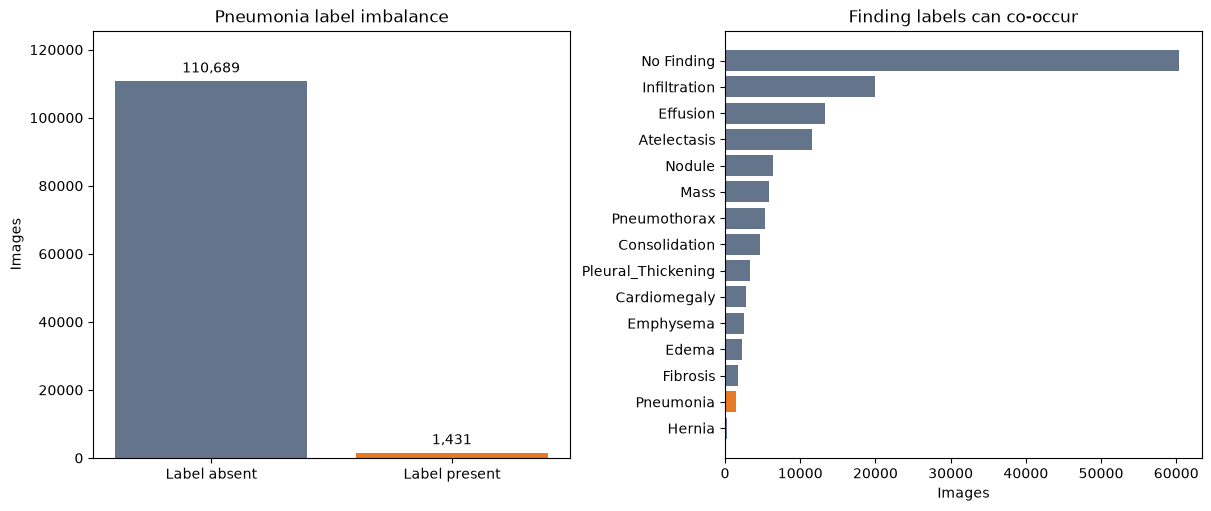

In [4]:
always_negative_accuracy = float(df.pneumonia.eq(0).mean())
print(f"모두 0으로 답할 때 정확도: {always_negative_accuracy:.2%}")
print("그 규칙의 양성 민감도: 0%")
finding_counts = label_tokens.explode().value_counts().sort_values()
finding_counts.rename_axis("finding").reset_index(name="images").to_csv(METRICS / "finding_counts.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
bars = axes[0].bar(["Label absent", "Label present"], class_table.images, color=["#64748b", "#e87924"])
axes[0].bar_label(bars, fmt="{:,.0f}", padding=4)
axes[0].set_ylim(0, len(df) * 1.12)
axes[0].set_title("Pneumonia label imbalance")
axes[0].set_ylabel("Images")
axes[1].barh(finding_counts.index, finding_counts.values, color=["#e87924" if x == "Pneumonia" else "#64748b" for x in finding_counts.index])
axes[1].set_title("Finding labels can co-occur")
axes[1].set_xlabel("Images")
fig.savefig(FIGURES / "class_and_finding_distribution.png", dpi=150)
plt.show()
plt.close(fig)

## 5. 환자별 영상 수와 반복 촬영 구조

환자별 영상 수의 요약 통계와 분포를 계산한다. 반복 촬영이 존재하면 영상 수를 독립 환자 수로 해석할 수 없으며, 영상 단위 무작위 분할은 동일 환자의 영상을 여러 그룹에 배치할 수 있다.

**결과:** 환자별 영상 수 중앙값은 1장, 최댓값은 184장이다. 영상이 2장 이상인 환자는 13,302명이며, Pneumonia 라벨 영상이 한 장 이상 있는 환자는 1,008명이다.

히스토그램의 세로축에는 로그 눈금을 사용하여 영상 수가 많은 소수 환자의 분포도 표시한다.

,images_per_patient
count,30805.000000
mean,3.639669
std,7.266734
min,1.000000
50%,1.000000
90%,8.000000
95%,14.000000
99%,35.000000
max,184.000000


영상 2장 이상 환자: 13,302명
폐렴 라벨 영상이 한 장 이상 있는 환자: 1,008명


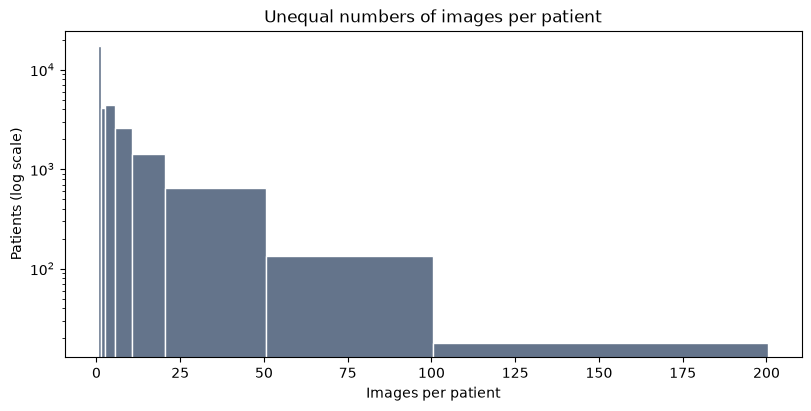

In [5]:
patients = df.groupby("Patient ID").agg(
    image_count=("Image Index", "size"),
    positive_images=("pneumonia", "sum"),
)
patient_stats = patients.image_count.describe(percentiles=[0.5, 0.9, 0.95, 0.99])
display(patient_stats.to_frame("images_per_patient"))
print(f"영상 2장 이상 환자: {patients.image_count.gt(1).sum():,}명")
print(f"폐렴 라벨 영상이 한 장 이상 있는 환자: {patients.positive_images.gt(0).sum():,}명")
patient_stats.to_csv(METRICS / "patient_image_count_statistics.csv")
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.hist(patients.image_count, bins=[0.5, 1.5, 2.5, 5.5, 10.5, 20.5, 50.5, 100.5, 200.5], color="#64748b", edgecolor="white")
ax.set_yscale("log")
ax.set_xlabel("Images per patient")
ax.set_ylabel("Patients (log scale)")
ax.set_title("Unequal numbers of images per patient")
fig.savefig(FIGURES / "images_per_patient.png", dpi=150)
plt.show()
plt.close(fig)

## 6. 촬영 자세별 분포와 폐렴 라벨 비율

PA/AP별 영상 수와 각 그룹 내 Pneumonia 라벨 비율을 집계한다. 그룹 크기가 다르므로 양성 영상 수와 양성 비율을 함께 제시한다. 동일 환자가 PA와 AP 영상을 모두 가질 수 있어 자세별 고유 환자 수는 서로 배타적인 집계가 아니다.

**결과:** AP는 44,810장 중 801장(1.788%), PA는 67,310장 중 630장(0.936%)이 양성 라벨을 갖는다.

**한계:** 관찰된 차이는 이 데이터에서의 연관성이다. 환자군, 촬영 상황과 기타 교란 요인이 통제되지 않았다. 이 분석만으로 촬영 자세의 인과적 효과나 모델의 자세 의존성을 판단하지 않는다. 전체 메타데이터를 이용한 기술적 분석이며 테스트 예측을 이용한 모델 선택은 수행하지 않았다.

,images,patients,positive_images,image_share_percent,positive_percent
View Position,,,,,
AP,44810,9060,801,39.966,1.788
PA,67310,28868,630,60.034,0.936


자세별 환자 집합은 상호 배타적이지 않음


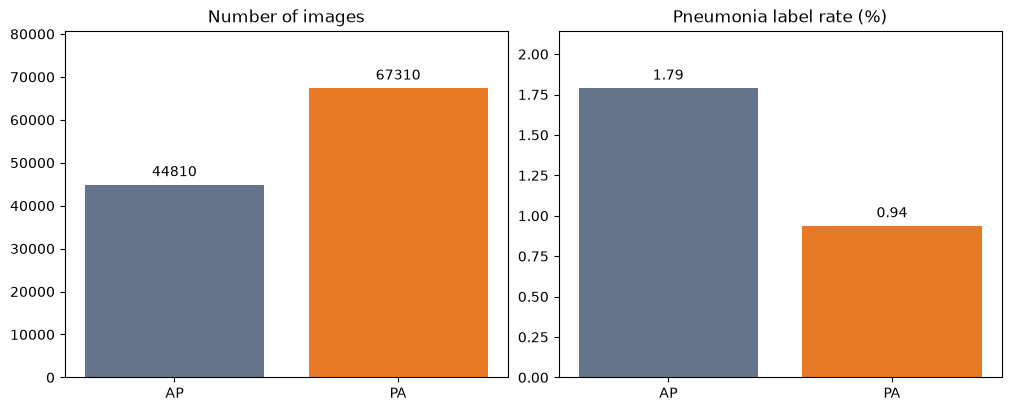

AP 양성 라벨 비율: 1.788%
PA 양성 라벨 비율: 0.936%


In [6]:
view_table = df.groupby("View Position").agg(
    images=("Image Index", "size"),
    patients=("Patient ID", "nunique"),
    positive_images=("pneumonia", "sum"),
)
view_table["image_share_percent"] = view_table.images / len(df) * 100
view_table["positive_percent"] = view_table.positive_images / view_table.images * 100
view_table.to_csv(METRICS / "view_position_summary.csv")
display(view_table.round(3))
print("자세별 환자 집합은 상호 배타적이지 않음")
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, column, title in [(axes[0], "images", "Number of images"), (axes[1], "positive_percent", "Pneumonia label rate (%)")]:
    bars = ax.bar(view_table.index, view_table[column], color=["#64748b", "#e87924"])
    ax.bar_label(bars, fmt="%.2f" if column == "positive_percent" else "%.0f", padding=4)
    ax.set_ylim(0, view_table[column].max() * 1.2)
    ax.set_title(title)
fig.savefig(FIGURES / "pa_ap_comparison.png", dpi=150)
plt.show()
plt.close(fig)
print(f"AP 양성 라벨 비율: {view_table.loc['AP', 'positive_percent']:.3f}%")
print(f"PA 양성 라벨 비율: {view_table.loc['PA', 'positive_percent']:.3f}%")

## 7. 영상 단위 무작위 분할의 환자 중복 분석

전체 메타데이터를 영상 기준 80/20으로 임시 분할하고, 양쪽에 공통으로 등장하는 환자 수와 해당 환자에 속한 평가 영상 비율을 계산한다. 난수 시드는 42로 고정한다.

이 분할은 환자 중복을 정량화하기 위한 비교 실험이다. 실제 학습이나 평가에 사용하지 않으며 기존 분할 파일로 저장하지 않는다. 운영 중인 70/15/15 환자 분할과는 별개다.

**결과:** 공통 환자는 8,028명이며 임시 평가 영상의 82.69%가 임시 학습 목록에 이미 등장하는 환자에 속한다. 이는 분할 독립성 위반을 보여 주지만, 그에 따른 모델 성능의 상승 폭은 측정하지 않았다.

In [7]:
bad_train, bad_test = train_test_split(df, test_size=0.20, random_state=42)
overlap = set(bad_train["Patient ID"]) & set(bad_test["Patient ID"])
overlap_image_percent = float(bad_test["Patient ID"].isin(overlap).mean() * 100)
print(f"영상 단위 분할의 중복 환자: {len(overlap):,}명")
print(f"임시 평가 영상 중 학습에서 이미 본 환자의 영상: {overlap_image_percent:.2f}%")
assert len(overlap) > 0
leakage_demo = {"temporary_test_fraction": 0.20, "overlapping_patients": len(overlap), "test_images_from_seen_patients_percent": overlap_image_percent, "used_for_training": False}
(METRICS / "image_split_leakage_demo.json").write_text(json.dumps(leakage_demo, indent=2), encoding="utf-8");

영상 단위 분할의 중복 환자: 8,028명
임시 평가 영상 중 학습에서 이미 본 환자의 영상: 82.69%


## 8. 원본·최초 환자 분할·현재 실험 목록의 구분

다음 세 규모를 구분하여 표본 축소와 QC의 영향을 추적한다.

| 구분 | 정의 |
|---|---|
| 원본 메타데이터 | 전체 영상 112,120장의 기술적 분석 기준 |
| 최초 환자 분할 | 환자별 Pneumonia 영상 보유 여부를 층화하여 환자 수 기준 약 70/15/15로 배정한 사용자 정의 분할 |
| 현재 실험 목록 | 최초 학습 그룹의 양성 1,019장과 무작위 음성 3,057장, 전체 검증·테스트 목록에서 정확한 픽셀 중복 6장을 제외한 목록 |

최초 분할은 NIH 공식 분할이 아니다. 분할과 학습 표본 선택에는 난수 시드 42를 사용했다. 현재 학습 양성 비율은 의도적으로 25%로 변경되었으며 검증·테스트에는 같은 비율 조정을 적용하지 않았다. 따라서 학습 표본의 빈도를 모집단의 질환 유병률로 해석할 수 없다.

아래에서는 기존 목록을 읽어 그룹 간 환자·파일명 중복과 최초 분할 소속 유지 여부를 검증한다. 분할을 새로 생성하거나 기존 표본을 재선정하지 않는다.

In [8]:
parent = {name: pd.read_csv(ROOT / f"data/processed/splits/{name}.csv", dtype={"Patient ID": str}) for name in ["train", "val", "test"]}
active = {name: pd.read_csv(ROOT / f"data/processed/reduced_train_full_eval_qc/{name}.csv", dtype={"Patient ID": str}) for name in ["train", "val", "test"]}
def summarize_splits(tables):
    rows = []
    for name, table in tables.items():
        rows.append({"split": name, "patients": table["Patient ID"].nunique(), "images": len(table), "positive_images": int(table.pneumonia.sum()), "positive_percent": table.pneumonia.mean() * 100})
    return pd.DataFrame(rows).set_index("split")
print("최초 환자 단위 분할")
display(summarize_splits(parent).round(3))
print("현재 사용할 QC 후 실험 목록")
active_summary = summarize_splits(active)
display(active_summary.round(3))
active_summary.to_csv(METRICS / "active_split_summary.csv")
for name, table in active.items():
    assert set(table["Image Index"]).issubset(set(parent[name]["Image Index"]))
for group_name, tables in [("parent", parent), ("active", active)]:
    for a, b in itertools.combinations(tables, 2):
        assert not set(tables[a]["Patient ID"]) & set(tables[b]["Patient ID"])
        assert not set(tables[a]["Image Index"]) & set(tables[b]["Image Index"])
print("기존 분할 소속 유지 / 그룹 간 환자와 파일명 중복 0 확인")

최초 환자 단위 분할


,patients,images,positive_images,positive_percent
split,,,,
train,21563,78517,1019,1.298
val,4621,16875,218,1.292
test,4621,16728,194,1.160


현재 사용할 QC 후 실험 목록


,patients,images,positive_images,positive_percent
split,,,,
train,2858,4076,1019,25.000
val,4621,16872,218,1.292
test,4621,16725,194,1.160


기존 분할 소속 유지 / 그룹 간 환자와 파일명 중복 0 확인


## 9. 픽셀 중복 제외 및 활성 목록 검증

선행 이미지 QC에서는 선택한 원본 37,679장 모두가 읽기 검사를 통과했다. 바이트 해시 중복은 없었지만 디코딩한 픽셀 기준으로 중복 쌍 6개가 확인되었고, 그중 한 쌍은 검증·테스트 목록에 걸쳐 있었다.

모델 성능을 확인하기 전에 고정한 규칙에 따라 테스트 > 검증 > 학습, 이후 파일명 순서로 한 장을 보존했다. 원본 파일은 보관하고 검증 3장·테스트 3장을 목록에서 제외했다. 모든 제외 대상의 이진 Pneumonia 타깃은 0이며, 원본 소견 라벨을 수정하지 않았다.

아래 검증은 기존 `image_inventory.csv`의 픽셀 해시와 활성 목록을 대조한다. 목록의 파일 존재 여부도 확인한다. 전체 영상의 디코딩 및 해시 계산을 다시 수행하는 셀은 아니며, 근사 중복의 부재를 보장하지 않는다.

In [9]:
qc_dir = ROOT / "outputs/metrics/dataset_qc"
exclusions = pd.read_csv(qc_dir / "duplicate_exclusions.csv")
display(exclusions[["Image Index", "split", "retained_image", "reason"]])
inventory = pd.read_csv(qc_dir / "image_inventory.csv", dtype={"Patient ID": str})
active_rows = pd.concat([table.assign(split=name) for name, table in active.items()], ignore_index=True)
checked = active_rows.merge(inventory[["image", "pixel_sha256", "mode", "width", "height"]], left_on="Image Index", right_on="image", validate="one_to_one")
assert len(checked) == len(active_rows) and not checked.pixel_sha256.isna().any()
assert not checked.pixel_sha256.duplicated().any()
missing_files = [name for name in active_rows["Image Index"] if not (ROOT / "data/raw/images" / name).is_file()]
assert not missing_files
print(f"활성 목록 {len(active_rows):,}장 / 파일 누락 0 / 정확한 픽셀 중복 0")
print("영상별 decode 및 픽셀 해시: 선행 QC 기록 사용")
assert hashlib.sha256(csv_path.read_bytes()).hexdigest() == source_hash
eda_summary = {"metadata_images": len(df), "patients": len(patients), "positive_images": int(df.pneumonia.sum()), "positive_percent": float(df.pneumonia.mean()*100), "always_negative_accuracy": always_negative_accuracy, "ap_positive_percent": float(view_table.loc['AP','positive_percent']), "pa_positive_percent": float(view_table.loc['PA','positive_percent']), "bad_split_overlapping_patients": len(overlap), "active_images": len(active_rows), "active_missing_files": len(missing_files), "active_exact_pixel_duplicates": 0, "source_csv_unchanged": True, "new_split_created": False}
(METRICS / "eda_summary.json").write_text(json.dumps(eda_summary, ensure_ascii=False, indent=2), encoding="utf-8")
print("EDA 결과 저장 완료")

,Image Index,split,retained_image,reason
0,00007670_031.png,test,00007670_030.png,Exact decoded-pixel duplicate; prefer test > v...
1,00016518_002.png,test,00016518_001.png,Exact decoded-pixel duplicate; prefer test > v...
2,00016568_053.png,test,00016568_052.png,Exact decoded-pixel duplicate; prefer test > v...
3,00005403_024.png,val,00005537_011.png,Exact decoded-pixel duplicate; prefer test > v...
4,00007633_004.png,val,00007633_003.png,Exact decoded-pixel duplicate; prefer test > v...
5,00015262_003.png,val,00015262_001.png,Exact decoded-pixel duplicate; prefer test > v...


활성 목록 37,673장 / 파일 누락 0 / 정확한 픽셀 중복 0
영상별 decode 및 픽셀 해시: 선행 QC 기록 사용
EDA 결과 저장 완료


## 10. 분석 결론 및 한계

### 확인된 데이터 특성
- Pneumonia 라벨 비율은 약 1.28%로 낮으며 정확도만으로 모델을 평가하기 어렵다.
- 환자별 반복 촬영이 존재한다. 영상 단위 비교 분할에서는 8,028명의 환자가 양쪽에 등장하여 독립성이 확보되지 않았다.
- AP와 PA의 양성 라벨 비율에 차이가 관찰된다. 원인이나 모델의 실제 의존성은 별도 검증 대상이다.
- 현재 실험 목록 37,673장은 원본 전체와 다른 구성이다. 학습 데이터의 음성 축소와 픽셀 중복 제외 내역을 구분하여 기록했다.
- 현재 목록에서 환자 중복, 파일 누락, 확인된 정확한 픽셀 중복은 0건이다.

### 남은 한계
- 소견 라벨의 임상적 정확성을 검증하지 않았다.
- 근사 중복 및 전체 영상의 육안 품질 검토는 완료하지 않았다.
- 촬영 자세 등 잠재 교란 요인에 대한 모델 의존성을 평가하지 않았다.
- 다른 기관 데이터로 외부 검증을 수행하지 않았다.
- 모델 학습·성능 추정·임계값 선택은 본 노트북의 범위가 아니다.

### 후속 작업
학습 영상의 전처리 전후 비교와 증강 강도 검토를 수행한 뒤 학습·평가용 입력 처리를 확정한다. 모델링에서는 이 노트북에서 확인한 불균형, 반복 촬영 구조 및 표본 선택의 영향을 반영하여 평가 계획을 수립한다.